# **Inverse Modeling of Reservoir Geometry: Statistical Analysis**
Compares the single-source and multi-source inversions of the Topography case.
The results loaded below are generated by the other notebooks in this directory (`Topography_inverse_*+*.ipynb`).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def RMSE(x, x_hat):
    return np.sqrt((x - x_hat) ** 2).mean()

# ***Statistical analysis:***

In [154]:
def calculate_metrics(reference, prediction, evaluate_dim):
    metrics = []
    if evaluate_dim == 0:
        print(f"Calculating RMSE for CO2 pressure...")
        ref_variable = reference[..., 0]
        pred_variable = prediction[..., 0]
        for i in range(pred_variable.shape[0]):
            for t in range(pred_variable.shape[1]):
                metric = RMSE(ref_variable[t, ...], pred_variable[i, t, ...])
                metrics.append(metric)
        metrics = np.array(metrics).reshape(pred_variable.shape[0], pred_variable.shape[1])
        print(f"RMSE shape: {metrics.shape}. Mean = {metrics.mean()}, Std = {metrics.std()}")
    
    elif evaluate_dim == 1:
        print(f"Calculating RMSE for CO2 saturation...")
        ref_variable = reference[..., 1]
        pred_variable = prediction[..., 1]
        for i in range(pred_variable.shape[0]):
            for t in range(pred_variable.shape[1]):
                metric = RMSE(ref_variable[t, ...], pred_variable[i, t, ...])
                metrics.append(metric)
        metrics = np.array(metrics).reshape(pred_variable.shape[0], pred_variable.shape[1])
        print(f"RMSE shape: {metrics.shape}. Mean = {metrics.mean()}, Std = {metrics.std()}")
    
    elif evaluate_dim == 2:
        print(f"Calculating RMSE for thickness...")
        ref_variable = reference[..., 2]
        pred_variable = prediction[..., 2]
        for i in range(pred_variable.shape[0]):
            metric = RMSE(ref_variable[0, ...], np.mean(pred_variable[i, ...], axis=0))
            metrics.append(metric)
        metrics = np.array(metrics)
        print(f"RMSE shape: {metrics.shape}. Mean = {metrics.mean()}, Std = {metrics.std()}")
    
    elif evaluate_dim == 3:
        print(f"Calculating RMSE for depth...")
        ref_variable = reference[..., 3]
        pred_variable = prediction[..., 3]
        for i in range(pred_variable.shape[0]):
            metric = RMSE(ref_variable[0, ...], np.mean(pred_variable[i, ...], axis=0))
            metrics.append(metric)
        metrics = np.array(metrics)
        print(f"RMSE shape: {metrics.shape}. Mean = {metrics.mean()}, Std = {metrics.std()}")
    
    else:
        raise ValueError("evaluate_dim must be 0, 1, 2, or 3.")
    
    return metrics

In [ ]:
ref = np.load('Topography_unstructured_outputs/npys/ref.npy')
pred_sparsewell_18 = np.load('Topography_unstructured_outputs/npys/CNF_out_sparsewell_noise_0.05.npy')
pred_co2seismic = np.load('Topography_unstructured_outputs/npys/CNF_out_co2seismic_noise_0.05.npy')
pred_geoseismic = np.load('Topography_unstructured_outputs/npys/CNF_out_geoseismic_noise_0.05.npy')

pred_sparsewell_and_co2seismic = np.load('Topography_unstructured_outputs/npys/CNF_out_sparsewell_and_co2seismic_noise_0.05.npy')
pred_sparsewell_and_geoseismic = np.load('Topography_unstructured_outputs/npys/CNF_out_sparsewell_and_geoseismic_noise_0.05.npy')
pred_co2seismic_and_geoseismic = np.load('Topography_unstructured_outputs/npys/CNF_out_co2seismic_and_geoseismic_noise_0.05.npy')
print(f"Reference shape: {ref.shape}, single source res shape: {pred_sparsewell_18.shape}, multi-source shape: {pred_sparsewell_and_co2seismic.shape}")

# below are different noise levels, dropped now...
pred_sparsewell_and_geoseismic_noisy_01 = np.load('Topography_unstructured_outputs/npys/CNF_out_sparsewell_and_geoseismic_noise_0.01.npy')
pred_sparsewell_and_geoseismic_noisy_05 = np.load('Topography_unstructured_outputs/npys/CNF_out_sparsewell_and_geoseismic_noise_0.01.npy')
pred_co2seismic_and_geoseismic_noisy_01 = np.load('Topography_unstructured_outputs/npys/CNF_out_co2seismic_and_geoseismic_noise_0.01.npy')
pred_co2seismic_and_geoseismic_noisy_05 = np.load('Topography_unstructured_outputs/npys/CNF_out_co2seismic_and_geoseismic_noise_0.05.npy')

Reference shape: (128, 7720, 4), single source res shape: (10, 128, 7720, 4), multi-source shape: (10, 128, 7720, 4)


### RMSE evaluation

In [155]:
metric_sg_sparsewell_18 = calculate_metrics(ref, pred_sparsewell_18, evaluate_dim=1)
metric_sg_co2seismic = calculate_metrics(ref, pred_co2seismic, evaluate_dim=1)
metric_sg_geoseismic = calculate_metrics(ref, pred_geoseismic, evaluate_dim=1)
print('-'*50)
metric_thickness_sparsewell_18 = calculate_metrics(ref, pred_sparsewell_18, evaluate_dim=2)
metric_thickness_co2seismic = calculate_metrics(ref, pred_co2seismic, evaluate_dim=2)
metric_thickness_geoseismic = calculate_metrics(ref, pred_geoseismic, evaluate_dim=2)
print('-'*50)
metric_depth_sparsewell_18 = calculate_metrics(ref, pred_sparsewell_18, evaluate_dim=3)
metric_depth_co2seismic = calculate_metrics(ref, pred_co2seismic, evaluate_dim=3)
metric_depth_geoseismic = calculate_metrics(ref, pred_geoseismic, evaluate_dim=3)

Calculating RMSE for CO2 saturation...
RMSE shape: (10, 128). Mean = 0.008970019407570362, Std = 0.004361930303275585
Calculating RMSE for CO2 saturation...
RMSE shape: (10, 128). Mean = 0.003624937729910016, Std = 0.0013132928870618343
Calculating RMSE for CO2 saturation...
RMSE shape: (10, 128). Mean = 0.009897986426949501, Std = 0.0035681368317455053
--------------------------------------------------
Calculating RMSE for thickness...
RMSE shape: (10,). Mean = 4.618090629577637, Std = 0.2123289555311203
Calculating RMSE for thickness...
RMSE shape: (10,). Mean = 6.6016058921813965, Std = 0.4756260812282562
Calculating RMSE for thickness...
RMSE shape: (10,). Mean = 0.6372288465499878, Std = 0.09668722748756409
--------------------------------------------------
Calculating RMSE for depth...
RMSE shape: (10,). Mean = 8.750751495361328, Std = 0.5251907706260681
Calculating RMSE for depth...
RMSE shape: (10,). Mean = 11.872794151306152, Std = 0.6278709769248962
Calculating RMSE for depth

In [156]:
metric_sg_sparsewell_and_co2seismic = calculate_metrics(ref, pred_sparsewell_and_co2seismic, evaluate_dim=1)
metric_sg_sparsewell_and_geoseismic = calculate_metrics(ref, pred_sparsewell_and_geoseismic, evaluate_dim=1)
metric_sg_co2seismic_and_geoseismic = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=1)
print('-'*50)
metric_thickness_sparsewell_and_co2seismic = calculate_metrics(ref, pred_sparsewell_and_co2seismic, evaluate_dim=2)
metric_thickness_sparsewell_and_geoseismic = calculate_metrics(ref, pred_sparsewell_and_geoseismic, evaluate_dim=2)
metric_thickness_co2seismic_and_geoseismic = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=2)
print('-'*50)
metric_depth_sparsewell_and_co2seismic = calculate_metrics(ref, pred_sparsewell_and_co2seismic, evaluate_dim=3)
metric_depth_sparsewell_and_geoseismic = calculate_metrics(ref, pred_sparsewell_and_geoseismic, evaluate_dim=3)
metric_depth_co2seismic_and_geoseismic = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=3)

Calculating RMSE for CO2 saturation...
RMSE shape: (10, 128). Mean = 0.004918786697089672, Std = 0.0017586700851097703
Calculating RMSE for CO2 saturation...
RMSE shape: (10, 128). Mean = 0.008237527683377266, Std = 0.004385681822896004
Calculating RMSE for CO2 saturation...
RMSE shape: (10, 128). Mean = 0.0039392756298184395, Std = 0.0012306037824600935
--------------------------------------------------
Calculating RMSE for thickness...
RMSE shape: (10,). Mean = 4.539357662200928, Std = 0.21269109845161438
Calculating RMSE for thickness...
RMSE shape: (10,). Mean = 1.2674391269683838, Std = 0.17773061990737915
Calculating RMSE for thickness...
RMSE shape: (10,). Mean = 0.6854027509689331, Std = 0.1188296228647232
--------------------------------------------------
Calculating RMSE for depth...
RMSE shape: (10,). Mean = 7.990950584411621, Std = 0.4594130218029022
Calculating RMSE for depth...
RMSE shape: (10,). Mean = 2.7390589714050293, Std = 0.4031161665916443
Calculating RMSE for dep

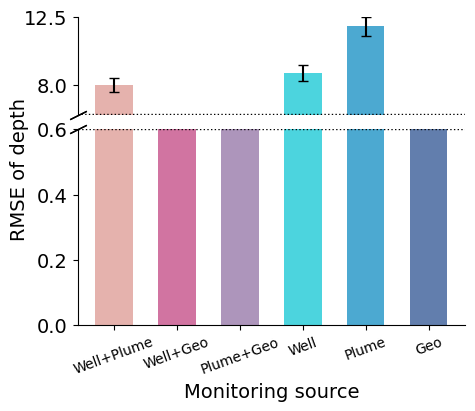

In [7]:
depths_mean = [metric_depth_sparsewell_and_co2seismic.mean(), metric_depth_sparsewell_and_geoseismic.mean(), metric_depth_co2seismic_and_geoseismic.mean(), metric_depth_sparsewell_18.mean(), metric_depth_co2seismic.mean(), metric_depth_geoseismic.mean()]
depths_std  = [metric_depth_sparsewell_and_co2seismic.std(),  metric_depth_sparsewell_and_geoseismic.std(),  metric_depth_co2seismic_and_geoseismic.std(), metric_depth_sparsewell_18.std(), metric_depth_co2seismic.std(), metric_depth_geoseismic.std()]

# groups = ['Sparse well + CO2 seismic', 'Sparse well + geo seismic', 'CO2 seismic + geo seismic']
groups = ['Well+Plume', 'Well+Geo', 'Plume+Geo', 'Well', 'Plume', 'Geo']
x = np.arange(len(groups))
colors_1 = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_2 = ["#00c2d1", "#0085be", "#20488a"]
colors = colors_1 + colors_2

width = 0.6

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(5, 4), gridspec_kw={'height_ratios': [1, 2]})
fig.subplots_adjust(hspace=0.1)

ax1.bar(x, depths_mean, width, yerr=depths_std, capsize=3.5, color=colors, ecolor='k', alpha=0.7)
ax2.bar(x, depths_mean, width, yerr=depths_std, capsize=3.5, color=colors, ecolor='k', alpha=0.7)

# for i in range(len(x)):
#     if i != 4:
#         ax2.text(x[i], depths_mean[i] + 0.4, f'{depths_mean[i]:.2f}',
#             ha='center', va='bottom', fontsize=10)
#     else:
#         ax2.text(x[i]+0.4, depths_mean[i] + 0.2, f'{depths_mean[i]:.2f}',
#             ha='center', va='bottom', fontsize=10)
    
    
ax1.set_ylim(6, 12.5)
ax2.set_ylim(0, 0.6)

d = 0.5
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=1, clip_on=False)
ax1.plot([0, 0], [0, 0], transform=ax1.transAxes, **kwargs)
ax2.plot([0, 0], [1, 1], transform=ax2.transAxes, **kwargs)
ax1.plot([0.01, 1], [0.01, 0.01], transform=ax1.transAxes, ls=':', color='k', lw=1)
ax2.plot([0, 1], [1, 1], transform=ax2.transAxes, ls=':', color='k', lw=1)

ax2.set_xticks(x)
ax2.set_xticklabels(groups)
ax1.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=10, rotation=20)
ax1.set_yticks([8, 12.5])

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.spines['bottom'].set_visible(False)
ax2.spines['bottom'].set_visible(True)
ax1.spines['right'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax1.tick_params(bottom=False, labelbottom=False)

fig.text(-0.01, 0.5, 'RMSE of depth', va='center', rotation='vertical', fontsize=14)
plt.xlabel('Monitoring source', fontsize=14)

# plt.savefig('Topography_unstructured_outputs/figs/monitoring_source_depth_[all].pdf', bbox_inches='tight')
plt.show()

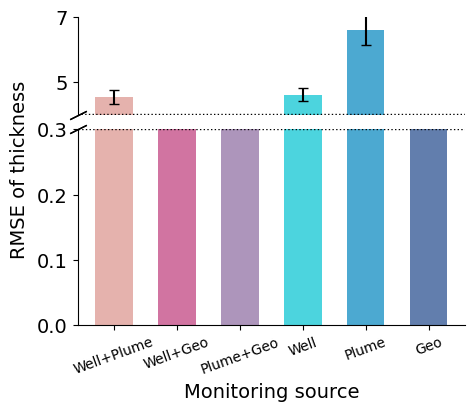

In [8]:
depths_mean = [metric_thickness_sparsewell_and_co2seismic.mean(), metric_thickness_sparsewell_and_geoseismic.mean(), metric_thickness_co2seismic_and_geoseismic.mean(), metric_thickness_sparsewell_18.mean(), metric_thickness_co2seismic.mean(), metric_thickness_geoseismic.mean()]
depths_std  = [metric_thickness_sparsewell_and_co2seismic.std(),  metric_thickness_sparsewell_and_geoseismic.std(),  metric_thickness_co2seismic_and_geoseismic.std(), metric_thickness_sparsewell_18.std(), metric_thickness_co2seismic.std(), metric_thickness_geoseismic.std()]

# groups = ['Sparse well + CO2 seismic', 'Sparse well + geo seismic', 'CO2 seismic + geo seismic']
groups = ['Well+Plume', 'Well+Geo', 'Plume+Geo', 'Well', 'Plume', 'Geo']
x = np.arange(len(groups))
colors_1 = ['#DB928AFF', '#BE3979FF', "#8B699EFF"]
colors_2 = ["#00c2d1", "#0085be", "#20488a"]
colors = colors_1 + colors_2

width = 0.6

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(5, 4), gridspec_kw={'height_ratios': [1, 2]})
fig.subplots_adjust(hspace=0.1)

ax1.bar(x, depths_mean, width, yerr=depths_std, capsize=3.5, color=colors, ecolor='k', alpha=0.7)
ax2.bar(x, depths_mean, width, yerr=depths_std, capsize=3.5, color=colors, ecolor='k', alpha=0.7)

# for i in range(len(x)):
#     if i != 4:
#         ax2.text(x[i], depths_mean[i] + 0.4, f'{depths_mean[i]:.2f}',
#             ha='center', va='bottom', fontsize=10)
#     else:
#         ax2.text(x[i]+0.4, depths_mean[i] + 0.2, f'{depths_mean[i]:.2f}',
#             ha='center', va='bottom', fontsize=10)
    
    
ax1.set_ylim(4, 7)
ax2.set_ylim(0, 0.3)

d = 0.5
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=1, clip_on=False)
ax1.plot([0, 0], [0, 0], transform=ax1.transAxes, **kwargs)
ax2.plot([0, 0], [1, 1], transform=ax2.transAxes, **kwargs)
ax1.plot([0.01, 1], [0.01, 0.01], transform=ax1.transAxes, ls=':', color='k', lw=1)
ax2.plot([0, 1], [1, 1], transform=ax2.transAxes, ls=':', color='k', lw=1)

ax2.set_xticks(x)
ax2.set_xticklabels(groups)
ax1.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=10, rotation=20)
ax1.set_yticks([5, 7])

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.spines['bottom'].set_visible(False)
ax2.spines['bottom'].set_visible(True)
ax1.spines['right'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax1.tick_params(bottom=False, labelbottom=False)

fig.text(-0.01, 0.5, 'RMSE of thickness', va='center', rotation='vertical', fontsize=14)
plt.xlabel('Monitoring source', fontsize=14)

# plt.savefig('Topography_unstructured_outputs/figs/monitoring_source_thickness_[all].pdf', bbox_inches='tight')
plt.show()

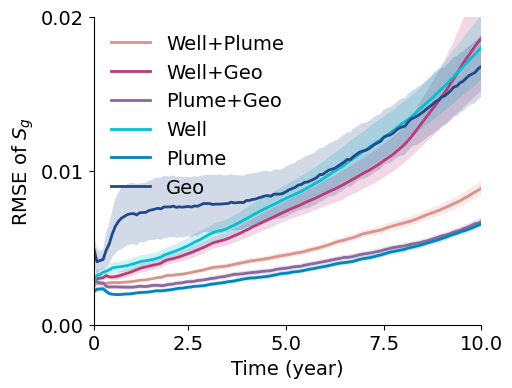

In [9]:
sg_list = [metric_sg_sparsewell_and_co2seismic, metric_sg_sparsewell_and_geoseismic, metric_sg_co2seismic_and_geoseismic, metric_sg_sparsewell_18, metric_sg_co2seismic, metric_sg_geoseismic]

colors_gen = ['#DB928AFF', '#BE3979FF', "#8B699EFF", "#00c2d1", "#0085be", "#20488a"]

groups = ['Well+Plume', 'Well+Geo', 'Plume+Geo', 'Well', 'Plume', 'Geo']

def plot_perm_mean_std(data, color, name):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    plt.plot(range(data.shape[-1]), mean, color=color, linewidth=2, label=name, ls='-')
    plt.fill_between(range(data.shape[-1]), mean - std, mean + std, color=color, alpha=0.2, edgecolor='none')
    
plt.figure(figsize=(5, 4))
for i in range(6):
    plot_perm_mean_std(sg_list[i], colors_gen[i], groups[i])

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 127)
plt.ylim(bottom=0, top=0.02)
plt.yticks([0, 0.01, 0.02], fontsize=14)
plt.xlabel('Time (year)', fontsize=14)
plt.ylabel('RMSE of $S_g$', fontsize=14)
plt.legend(fontsize=14, loc='upper left', frameon=False)

# plt.savefig('Topography_unstructured_outputs/figs/monitoring_source_sg_[all].pdf', bbox_inches='tight')

In [ ]:
metric_sg_co2seismic_and_geoseismic_noise_00 = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=1)
metric_sg_co2seismic_and_geoseismic_noise_01 = calculate_metrics(ref, pred_co2seismic_and_geoseismic_noisy_01, evaluate_dim=1)
metric_sg_co2seismic_and_geoseismic_noise_05 = calculate_metrics(ref, pred_co2seismic_and_geoseismic_noisy_05, evaluate_dim=1)
print('-'*50)
metric_thickness_co2seismic_and_geoseismic_noise_00 = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=2)
metric_thickness_co2seismic_and_geoseismic_noise_01 = calculate_metrics(ref, pred_co2seismic_and_geoseismic_noisy_01, evaluate_dim=2)
metric_thickness_co2seismic_and_geoseismic_noise_05 = calculate_metrics(ref, pred_co2seismic_and_geoseismic_noisy_05, evaluate_dim=2)
print('-'*50)
metric_depth_co2seismic_and_geoseismic_noise_00 = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=3)
metric_depth_co2seismic_and_geoseismic_noise_01 = calculate_metrics(ref, pred_co2seismic_and_geoseismic_noisy_01, evaluate_dim=3)
metric_depth_co2seismic_and_geoseismic_noise_05 = calculate_metrics(ref, pred_co2seismic_and_geoseismic_noisy_05, evaluate_dim=3)

In [164]:
def plot_triangle_radar(mean, std, var_limits, color="C0", label="", fig=None, ax=None):
    var_names = ['Depth', 'Thickness', r'$S_g$']
    # var_limits = [(1000, 1800), (0, 40), (20, 45)]

    assert len(mean) == len(std) == 3, "only 3 variables are supported"

    angles = np.linspace(0, 2 * np.pi, 3, endpoint=False).tolist()
    angles += angles[:1]

    def normalize(val, vmin, vmax):
        return (val - vmin) / (vmax - vmin)

    mean_norm = [normalize(mean[i], *var_limits[i]) for i in range(3)] + [normalize(mean[0], *var_limits[0])]
    std_norm  = [std[i] / (var_limits[i][1] - var_limits[i][0]) for i in range(3)] + [std[0] / (var_limits[0][1] - var_limits[0][0])]

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))
    ax.set_theta_offset(np.pi / 2)
    ax.set_frame_on(False)

    ax.xaxis.grid(False)
    ax.yaxis.grid(False)

    axis_r = np.linspace(0, 1.0, 100)
    for angle in angles[:-1]:
        ax.plot([angle]*len(axis_r), axis_r, color='k', linewidth=1.0, ls='--')

    for r in np.linspace(0.2, 1.0, 5):
        ax.plot(angles, [r]*len(angles), color='k', linewidth=0.6, linestyle=':')

    ax.plot(angles, mean_norm, color=color, linewidth=0)
    ax.fill(angles, mean_norm, color=color, alpha=0.5)

    # scatter + error bar + cap
    desired_cap_len = 0.02

    for i in range(3):
        theta = angles[i]
        r = mean_norm[i]
        e = std_norm[i]
        ax.scatter(theta, r, color=color, s=20, zorder=3)
        ax.plot([theta, theta], [r - e, r + e], color=color, linewidth=2)
        cap_width_upper = desired_cap_len / (r + e)
        cap_width_lower = desired_cap_len / (r - e)
        ax.plot([theta - cap_width_upper, theta + cap_width_upper], [r + e, r + e],
                color=color, linewidth=2)
        ax.plot([theta - cap_width_lower, theta + cap_width_lower], [r - e, r - e],
                color=color, linewidth=2)

    # ax.set_thetagrids(np.degrees(angles[:-1]), var_names, fontsize=12)
    label_radius = [1.15, 1.18, 1.18]
    for i, label_text in enumerate(var_names):
        angle = angles[i]
        ax.text(angle, label_radius[i], label_text,
                ha='center', va='center', fontsize=12,
                rotation=0)
    ax.set_yticklabels([])
    ax.set_xticks([])
    ax.set_rlabel_position(0)

    rotation = [0, 30, -30]
    for i, (vmin, vmax) in enumerate(var_limits):
        theta = angles[i]
        ticks = np.linspace(vmin, vmax, 4)
        for t in ticks[1:]:
            r = normalize(t, vmin, vmax)
            if i != 2:
                ax.text(theta, r-r*0.05, f"{t:.1f}",
                        ha='left', va='center', fontsize=10,
                        rotation=rotation[i])
            else:
                ax.text(theta, r-r*0.09, f"{t:.3f}",
                        ha='left', va='center', fontsize=10,
                        rotation=rotation[i])

    if label:
        from matplotlib.patches import Patch
        legend_patch = Patch(color=color, label=label)
        ax.legend(handles=[legend_patch], loc='lower center', bbox_to_anchor=(0.5, 0.15),
                  fontsize=12, frameon=False, handlelength=1.5)

    # plt.tight_layout()
    # plt.show()
    return fig


def plot_triangle_radar_integrated(mean, std, var_limits, color="C0", label="", fig=None, ax=None, draw_bg=True):
    var_names = ['Depth', 'Thickness', r'$S_g$']

    assert len(mean) == len(std) == 3, "only 3 variables are supported"

    angles = np.linspace(0, 2 * np.pi, 3, endpoint=False).tolist()
    angles += angles[:1]

    def normalize(val, vmin, vmax):
        return (val - vmin) / (vmax - vmin)

    mean_norm = [normalize(mean[i], *var_limits[i]) for i in range(3)] + [normalize(mean[0], *var_limits[0])]
    std_norm  = [std[i] / (var_limits[i][1] - var_limits[i][0]) for i in range(3)] + [std[0] / (var_limits[0][1] - var_limits[0][0])]

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))
    ax.set_theta_offset(np.pi / 2)
    ax.set_frame_on(False)

    ax.xaxis.grid(False)
    ax.yaxis.grid(False)

    if draw_bg:
        axis_r = np.linspace(0, 1.0, 100)
        for angle in angles[:-1]:
            ax.plot([angle]*len(axis_r), axis_r, color='gray', linewidth=1.0, ls='--')

        for r in np.linspace(0.2, 1.0, 5):
            ax.plot(angles, [r]*len(angles), color='gray', linewidth=0.6, linestyle=':')

    ax.plot(angles, mean_norm, color=color, linewidth=1)
    ax.fill(angles, mean_norm, color=color, alpha=0.1)

    # scatter + error bar + cap
    desired_cap_len = 0.02

    for i in range(3):
        theta = angles[i]
        r = mean_norm[i]
        e = std_norm[i]
        ax.scatter(theta, r, color=color, s=10, zorder=3)
        ax.plot([theta, theta], [r - e, r + e], color=color, linewidth=1)
        cap_width_upper = desired_cap_len / (r + e)
        cap_width_lower = desired_cap_len / (r - e)
        ax.plot([theta - cap_width_upper, theta + cap_width_upper], [r + e, r + e],
                color=color, linewidth=1)
        ax.plot([theta - cap_width_lower, theta + cap_width_lower], [r - e, r - e],
                color=color, linewidth=1)

    if draw_bg:
        label_radius = [1.15, 1.18, 1.18]
        for i, label_text in enumerate(var_names):
            angle = angles[i]
            ax.text(angle, label_radius[i], label_text,
                    ha='center', va='center', fontsize=12,
                    rotation=0)

        rotation = [0, 30, -30]
        for i, (vmin, vmax) in enumerate(var_limits):
            theta = angles[i]
            ticks = np.linspace(vmin, vmax, 4)
            for t in ticks[1:]:
                r = normalize(t, vmin, vmax)
                if i != 2:
                    ax.text(theta, r-r*0.05, f"{t:.1f}",
                            ha='left', va='center', fontsize=10,
                            rotation=rotation[i])
                else:
                    ax.text(theta, r-r*0.09, f"{t:.3f}",
                            ha='left', va='center', fontsize=10,
                            rotation=rotation[i])

    ax.set_yticklabels([])
    ax.set_xticks([])
    ax.set_rlabel_position(0)

    if label:
        from matplotlib.patches import Patch
        legend_patch = Patch(color=color, label=label)
        ax.legend(handles=[legend_patch], loc='lower center', bbox_to_anchor=(0.5, 0.15),
                  fontsize=12, frameon=False, handlelength=1.5)

    return fig
var_limits = [(0, 12), (0, 9), (0, 0.018)]

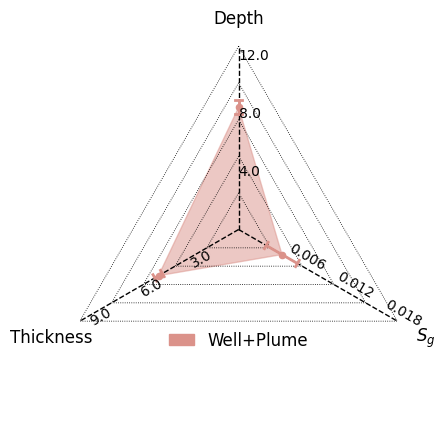

In [9]:
mean = [metric_depth_sparsewell_and_co2seismic.mean(), metric_thickness_sparsewell_and_co2seismic.mean(), metric_sg_sparsewell_and_co2seismic.mean()]
std  = [metric_depth_sparsewell_and_co2seismic.std(), metric_thickness_sparsewell_and_co2seismic.std(), metric_sg_sparsewell_and_co2seismic.std()]

fig = plot_triangle_radar(mean, std, var_limits, color="#DB928AFF", label="Well+Plume")
fig.savefig('Topography_unstructured_outputs/figs/radar_well+plume.pdf', bbox_inches='tight')

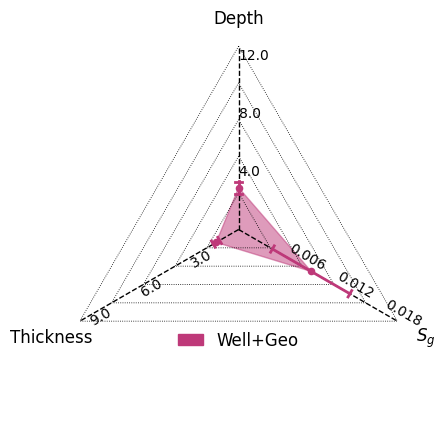

In [10]:
mean = [metric_depth_sparsewell_and_geoseismic.mean(), metric_thickness_sparsewell_and_geoseismic.mean(), metric_sg_sparsewell_and_geoseismic.mean()]
std  = [metric_depth_sparsewell_and_geoseismic.std(), metric_thickness_sparsewell_and_geoseismic.std(), metric_sg_sparsewell_and_geoseismic.std()]

fig = plot_triangle_radar(mean, std, var_limits, color="#BE3979FF", label="Well+Geo")
fig.savefig('Topography_unstructured_outputs/figs/radar_well+geo.pdf', bbox_inches='tight')

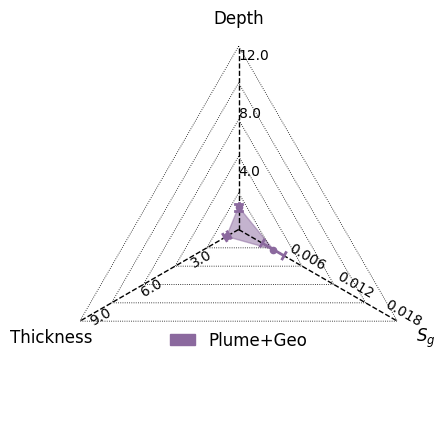

In [11]:
mean = [metric_depth_co2seismic_and_geoseismic.mean(), metric_thickness_co2seismic_and_geoseismic.mean(), metric_sg_co2seismic_and_geoseismic.mean()]
std  = [metric_depth_co2seismic_and_geoseismic.std(), metric_thickness_co2seismic_and_geoseismic.std(), metric_sg_co2seismic_and_geoseismic.std()]

fig = plot_triangle_radar(mean, std, var_limits, color="#8B699EFF", label="Plume+Geo")
fig.savefig('Topography_unstructured_outputs/figs/radar_co2+geo.pdf', bbox_inches='tight')

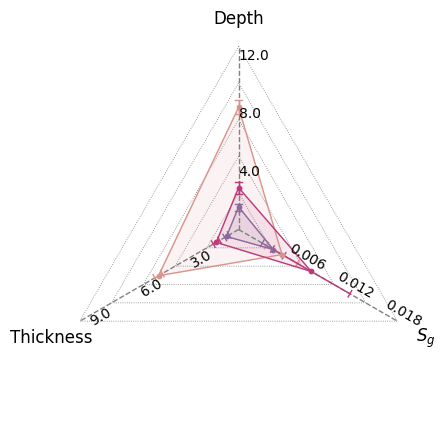

In [165]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))


mean = [metric_depth_sparsewell_and_co2seismic.mean(), metric_thickness_sparsewell_and_co2seismic.mean(), metric_sg_sparsewell_and_co2seismic.mean()]
std  = [metric_depth_sparsewell_and_co2seismic.std(), metric_thickness_sparsewell_and_co2seismic.std(), metric_sg_sparsewell_and_co2seismic.std()]

fig = plot_triangle_radar_integrated(mean, std, var_limits, color="#DB928AFF", label=False, fig=fig,ax=ax, draw_bg=True)
# fig.savefig('Topography_unstructured_outputs/figs/radar_well+plume.pdf', bbox_inches='tight')

mean = [metric_depth_sparsewell_and_geoseismic.mean(), metric_thickness_sparsewell_and_geoseismic.mean(), metric_sg_sparsewell_and_geoseismic.mean()]
std  = [metric_depth_sparsewell_and_geoseismic.std(), metric_thickness_sparsewell_and_geoseismic.std(), metric_sg_sparsewell_and_geoseismic.std()]

fig = plot_triangle_radar_integrated(mean, std, var_limits, color="#BE3979FF", label=False, fig=fig, ax=ax, draw_bg=False)
# fig.savefig('Topography_unstructured_outputs/figs/radar_well+geo.pdf', bbox_inches='tight')

mean = [metric_depth_co2seismic_and_geoseismic.mean(), metric_thickness_co2seismic_and_geoseismic.mean(), metric_sg_co2seismic_and_geoseismic.mean()]
std  = [metric_depth_co2seismic_and_geoseismic.std(), metric_thickness_co2seismic_and_geoseismic.std(), metric_sg_co2seismic_and_geoseismic.std()]

fig = plot_triangle_radar_integrated(mean, std, var_limits, color="#8B699EFF", label=False, fig=fig, ax=ax, draw_bg=False)
fig.savefig('Topography_unstructured_outputs/figs/[rebuttle]radar_multi_source.pdf', bbox_inches='tight')
plt.show()

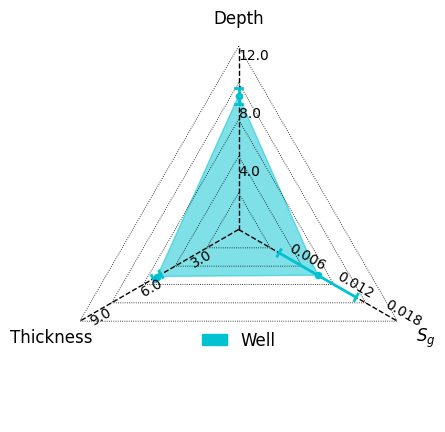

In [12]:
mean = [metric_depth_sparsewell_18.mean(), metric_thickness_sparsewell_18.mean(), metric_sg_sparsewell_18.mean()]
std  = [metric_depth_sparsewell_18.std(), metric_thickness_sparsewell_18.std(), metric_sg_sparsewell_18.std()]

fig = plot_triangle_radar(mean, std, var_limits, color="#00c2d1", label="Well")
fig.savefig('Topography_unstructured_outputs/figs/radar_well.pdf', bbox_inches='tight')

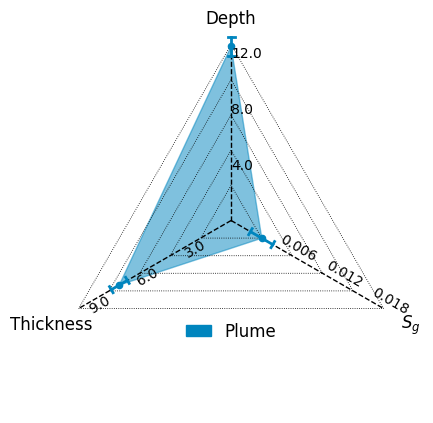

In [13]:
mean = [metric_depth_co2seismic.mean(), metric_thickness_co2seismic.mean(), metric_sg_co2seismic.mean()]
std  = [metric_depth_co2seismic.std(), metric_thickness_co2seismic.std(), metric_sg_co2seismic.std()]

fig = plot_triangle_radar(mean, std, var_limits, color="#0085be", label="Plume")
fig.savefig('Topography_unstructured_outputs/figs/radar_plume.pdf', bbox_inches='tight')

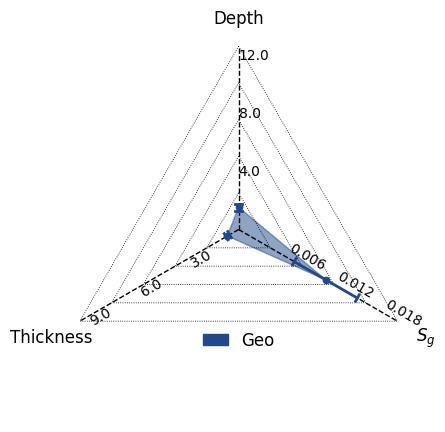

In [14]:
mean = [metric_depth_geoseismic.mean(), metric_thickness_geoseismic.mean(), metric_sg_geoseismic.mean()]
std  = [metric_depth_geoseismic.std(), metric_thickness_geoseismic.std(), metric_sg_geoseismic.std()]

fig = plot_triangle_radar(mean, std, var_limits, color="#20488a", label="Geo")
fig.savefig('Topography_unstructured_outputs/figs/radar_geo.pdf', bbox_inches='tight')

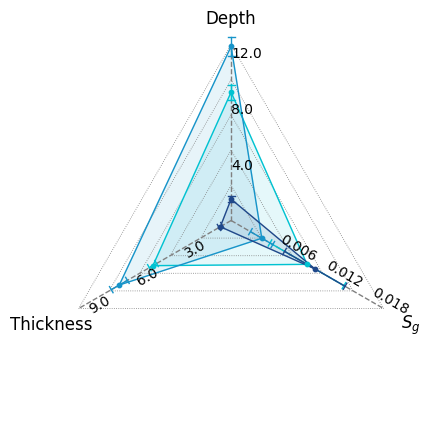

In [36]:
fig, ax = plt.subplots(figsize=(5, 5), subplot_kw=dict(polar=True))


mean = [metric_depth_sparsewell_18.mean(), metric_thickness_sparsewell_18.mean(), metric_sg_sparsewell_18.mean()]
std  = [metric_depth_sparsewell_18.std(), metric_thickness_sparsewell_18.std(), metric_sg_sparsewell_18.std()]

fig = plot_triangle_radar_integrated(mean, std, var_limits, color="#00c2d1", label=False, fig=fig,ax=ax, draw_bg=True)
# fig.savefig('Topography_unstructured_outputs/figs/radar_well+plume.pdf', bbox_inches='tight')

mean = [metric_depth_co2seismic.mean(), metric_thickness_co2seismic.mean(), metric_sg_co2seismic.mean()]
std  = [metric_depth_co2seismic.std(), metric_thickness_co2seismic.std(), metric_sg_co2seismic.std()]

fig = plot_triangle_radar_integrated(mean, std, var_limits, color="#1794c9", label=False, fig=fig, ax=ax, draw_bg=False)
# fig.savefig('Topography_unstructured_outputs/figs/radar_well+geo.pdf', bbox_inches='tight')

mean = [metric_depth_geoseismic.mean(), metric_thickness_geoseismic.mean(), metric_sg_geoseismic.mean()]
std  = [metric_depth_geoseismic.std(), metric_thickness_geoseismic.std(), metric_sg_geoseismic.std()]

fig = plot_triangle_radar_integrated(mean, std, var_limits, color="#20488a", label=False, fig=fig, ax=ax, draw_bg=False)
fig.savefig('Topography_unstructured_outputs/figs/[rebuttle]radar_single_source.pdf', bbox_inches='tight')
plt.show()

In [4]:
metric_p_sparsewell_and_co2seismic = calculate_metrics(ref, pred_sparsewell_and_co2seismic, evaluate_dim=0)
metric_p_sparsewell_and_geoseismic = calculate_metrics(ref, pred_sparsewell_and_geoseismic, evaluate_dim=0)
metric_p_co2seismic_and_geoseismic = calculate_metrics(ref, pred_co2seismic_and_geoseismic, evaluate_dim=0)

metric_p_sparsewell_18 = calculate_metrics(ref, pred_sparsewell_18, evaluate_dim=0)
metric_p_co2seismic = calculate_metrics(ref, pred_co2seismic, evaluate_dim=0)
metric_p_geoseismic = calculate_metrics(ref, pred_geoseismic, evaluate_dim=0)

Calculating RMSE for CO2 pressure...
RMSE shape: (10, 128). Mean = 78717.1640625, Std = 4766.1513671875
Calculating RMSE for CO2 pressure...
RMSE shape: (10, 128). Mean = 31924.67578125, Std = 4879.44873046875
Calculating RMSE for CO2 pressure...
RMSE shape: (10, 128). Mean = 51048.66796875, Std = 13036.1630859375
Calculating RMSE for CO2 pressure...
RMSE shape: (10, 128). Mean = 86040.0859375, Std = 6100.77685546875
Calculating RMSE for CO2 pressure...
RMSE shape: (10, 128). Mean = 224552.125, Std = 94083.125
Calculating RMSE for CO2 pressure...
RMSE shape: (10, 128). Mean = 48775.2265625, Std = 15526.90625


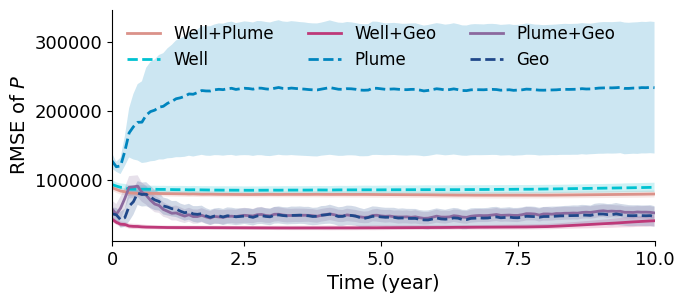

In [20]:
def plot_func(arr, c, ls, label):
    mean = np.mean(arr, axis=0)
    std = np.std(arr, axis=0)
    plt.plot(range(128), mean, color=c, linewidth=2, ls=ls, label=label)
    plt.fill_between(range(128), mean - std, mean + std, color=c, alpha=0.2, edgecolor='none')
    
plt.figure(figsize=(7, 3))
plot_func(metric_p_sparsewell_and_co2seismic, "#DB928AFF", '-', 'Well+Plume')
plot_func(metric_p_sparsewell_18, "#00c2d1", '--', 'Well')
plot_func(metric_p_sparsewell_and_geoseismic, "#BE3979FF", '-', 'Well+Geo')
plot_func(metric_p_co2seismic, "#0085be", '--', 'Plume')
plot_func(metric_p_co2seismic_and_geoseismic, "#8B699EFF", '-', 'Plume+Geo')
plot_func(metric_p_geoseismic, "#20488a", '--', 'Geo')

plt.xlabel('Time (year)', fontsize=14)
plt.ylabel('RMSE of $P$', fontsize=14)
plt.legend(frameon=False, loc='upper left', fontsize=12, ncol=3)
plt.xlim(0, 127)
# plt.yscale("log")
labels = [0, 2.5, 5.0, 7.5, 10.0]
positions = [int(x * 127 / 10.0) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.tick_params(axis='both', labelsize=13)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('Topography_unstructured_outputs/figs/pressure.pdf', bbox_inches='tight')
plt.show()

## Variogram evaluation

In [ ]:
gt_thickness = ref[0, :, 2]
gt_depth = ref[0, :, 3]
gt_sat = ref[-1, :, 1]

sparsewell_18_thickness = pred_sparsewell_18[..., 2].mean(axis=1)
sparsewell_18_depth = pred_sparsewell_18[..., 3].mean(axis=1)
sparse_well_sat = pred_sparsewell_18[:, -1, :, 1]
co2seismic_thickness = pred_co2seismic[..., 2].mean(axis=1)
co2seismic_depth = pred_co2seismic[..., 3].mean(axis=1)
co2_seismic_sat = pred_co2seismic[:, -1, :, 1]
geoseismic_thickness = pred_geoseismic[..., 2].mean(axis=1)
geoseismic_depth = pred_geoseismic[..., 3].mean(axis=1)
geo_seismic_sat = pred_geoseismic[:, -1, :, 1]


sparsewell_and_co2seismic_thickness = pred_sparsewell_and_co2seismic[..., 2].mean(axis=1)
sparsewell_and_co2seismic_depth = pred_sparsewell_and_co2seismic[..., 3].mean(axis=1)
sparsewell_and_co2seismic_sat = pred_sparsewell_and_co2seismic[:, -1, :, 1]
sparsewell_and_geoseismic_thickness = pred_sparsewell_and_geoseismic[..., 2].mean(axis=1)
sparsewell_and_geoseismic_depth = pred_sparsewell_and_geoseismic[..., 3].mean(axis=1)
sparsewell_and_geoseismic_sat = pred_sparsewell_and_geoseismic[:, -1, :, 1]
co2seismic_and_geoseismic_thickness = pred_co2seismic_and_geoseismic[..., 2].mean(axis=1)
co2seismic_and_geoseismic_depth = pred_co2seismic_and_geoseismic[..., 3].mean(axis=1)
co2seismic_and_geoseismic_sat = pred_co2seismic_and_geoseismic[:, -1, :, 1]

In [34]:
coords = np.load('../../../Dataset/unstructured_coords.npy')
print(coords.shape, coords[:, 0].min(), coords[:, 0].max(), coords[:, 1].min(), coords[:, 1].max())

def eval_vario(field):
    import gstools as gs
    
    x = coords[:, 0]
    y = coords[:, 1]
    
    bin, gamma = gs.vario_estimate((x, y), field)
    
    fit_model = gs.Gaussian(dim=2)
    fit_model.fit_variogram(bin, gamma, nugget=False)
    return bin, gamma, fit_model

def eval_vario_samples(fields):
    bin_list, gamma_list, fit_model_list = [], [], []
    for i in range(fields.shape[0]):
        bin, gamma, fit_model = eval_vario(fields[i])
        bin_list.append(bin)
        gamma_list.append(gamma)
        fit_model_list.append(fit_model)
    return bin_list, gamma_list, fit_model_list

def dykstra_parsons(k):
    if k.ndim == 1:
        k16 = np.quantile(k, 0.16)
        k50 = np.quantile(k, 0.5)
        dp = (k50 - k16) / k50
    elif k.ndim == 2:
        dp = np.array([(np.quantile(k[i], 0.5) - np.quantile(k[i], 0.16)) / np.quantile(k[i], 0.5) 
                        for i in range(k.shape[0])])
    return dp

(7720, 2) 13.82011 3181.581 15.09132 5885.451


In [36]:
gt_bin, gt_gamma, gt_fit_model = eval_vario(gt_thickness)
sparsewell_18_bin, sparsewell_18_gamma, sparsewell_18_fit_model = eval_vario_samples(sparsewell_18_thickness)
co2seismic_bin, co2seismic_gamma, co2seismic_fit_model = eval_vario_samples(co2seismic_thickness)
geoseismic_bin, geoseismic_gamma, geoseismic_fit_model = eval_vario_samples(geoseismic_thickness)
sparsewell_and_co2seismic_bin, sparsewell_and_co2seismic_gamma, sparsewell_and_co2seismic_fit_model = eval_vario_samples(sparsewell_and_co2seismic_thickness)
sparsewell_and_geoseismic_bin, sparsewell_and_geoseismic_gamma, sparsewell_and_geoseismic_fit_model = eval_vario_samples(sparsewell_and_geoseismic_thickness)
co2seismic_and_geoseismic_bin, co2seismic_and_geoseismic_gamma, co2seismic_and_geoseismic_fit_model = eval_vario_samples(co2seismic_and_geoseismic_thickness)

In [35]:
gt_dp = dykstra_parsons(gt_thickness)
sparsewell_18_dp = dykstra_parsons(sparsewell_18_thickness)
co2seismic_dp = dykstra_parsons(co2seismic_thickness)
geoseismic_dp = dykstra_parsons(geoseismic_thickness)
sparsewell_and_co2seismic_dp = dykstra_parsons(sparsewell_and_co2seismic_thickness)
sparsewell_and_geoseismic_dp = dykstra_parsons(sparsewell_and_geoseismic_thickness)
co2seismic_and_geoseismic_dp = dykstra_parsons(co2seismic_and_geoseismic_thickness)

In [89]:
gt_fit_model, len(gt_bin), gt_bin

(Gaussian(dim=2, var=71.6, len_scale=5.49e+02, nugget=0.0),
 27,
 array([  41.17604805,  123.52814415,  205.88024025,  288.23233635,
         370.58443245,  452.93652855,  535.28862465,  617.64072075,
         699.99281686,  782.34491296,  864.69700906,  947.04910516,
        1029.40120126, 1111.75329736, 1194.10539346, 1276.45748956,
        1358.80958566, 1441.16168176, 1523.51377786, 1605.86587396,
        1688.21797006, 1770.57006616, 1852.92216226, 1935.27425836,
        2017.62635446, 2099.97845057, 2182.33054667]))

In [39]:
def get_plotable_bin_gamma_len(bin, fit_model):
    bin_list = []
    gamma_list = []
    len_list = []
    for i in range(len(bin)):
        bin_list.append(bin[i])
        gamma_list.append(fit_model[i].variogram(bin[i]))
        len_list.append(fit_model[i].len_scale)
    return bin_list, gamma_list, len_list

sparsewell_18_bin_list, sparsewell_18_gamma_list, sparsewell_18_len_list = get_plotable_bin_gamma_len(sparsewell_18_bin, sparsewell_18_fit_model)
co2seismic_bin_list, co2seismic_gamma_list, co2seismic_len_list = get_plotable_bin_gamma_len(co2seismic_bin, co2seismic_fit_model)
geoseismic_bin_list, geoseismic_gamma_list, geoseismic_len_list = get_plotable_bin_gamma_len(geoseismic_bin, geoseismic_fit_model)
sparsewell_and_co2seismic_bin_list, sparsewell_and_co2seismic_gamma_list, sparsewell_and_co2seismic_len_list = get_plotable_bin_gamma_len(sparsewell_and_co2seismic_bin, sparsewell_and_co2seismic_fit_model)
sparsewell_and_geoseismic_bin_list, sparsewell_and_geoseismic_gamma_list, sparsewell_and_geoseismic_len_list = get_plotable_bin_gamma_len(sparsewell_and_geoseismic_bin, sparsewell_and_geoseismic_fit_model)
co2seismic_and_geoseismic_bin_list, co2seismic_and_geoseismic_gamma_list, co2seismic_and_geoseismic_len_list = get_plotable_bin_gamma_len(co2seismic_and_geoseismic_bin, co2seismic_and_geoseismic_fit_model)

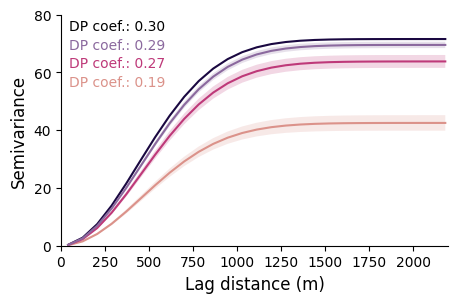

In [110]:
plt.figure(figsize=(5, 3))
plt.plot(gt_bin, gt_fit_model.variogram(gt_bin), label='Reference', color='#1a0841', linestyle='-', linewidth=1.5)


# ---multi source---

multicolors = ['#DB928AFF', '#BE3979FF', '#8B699EFF']
lebels = ['Well+Plume', 'Well+Geo', 'Plume+Geo']


plt.plot(gt_bin, np.mean(sparsewell_and_co2seismic_gamma_list, axis=0), color=multicolors[0], linestyle='-', linewidth=1.5, label=lebels[0])
plt.fill_between(gt_bin, np.mean(sparsewell_and_co2seismic_gamma_list, axis=0) - np.std(sparsewell_and_co2seismic_gamma_list, axis=0), 
                 np.mean(sparsewell_and_co2seismic_gamma_list, axis=0) + np.std(sparsewell_and_co2seismic_gamma_list, axis=0), 
                 color=multicolors[0], alpha=0.2, edgecolor='none')

plt.plot(gt_bin, np.mean(sparsewell_and_geoseismic_gamma_list, axis=0), color=multicolors[1], linestyle='-', linewidth=1.5, label=lebels[1])
plt.fill_between(gt_bin, np.mean(sparsewell_and_geoseismic_gamma_list, axis=0) - np.std(sparsewell_and_geoseismic_gamma_list, axis=0), 
                 np.mean(sparsewell_and_geoseismic_gamma_list, axis=0) + np.std(sparsewell_and_geoseismic_gamma_list, axis=0), 
                 color=multicolors[1], alpha=0.2, edgecolor='none')

plt.plot(gt_bin, np.mean(co2seismic_and_geoseismic_gamma_list, axis=0), color=multicolors[2], linestyle='-', linewidth=1.5, label=lebels[2])
plt.fill_between(gt_bin, np.mean(co2seismic_and_geoseismic_gamma_list, axis=0) - np.std(co2seismic_and_geoseismic_gamma_list, axis=0), 
                 np.mean(co2seismic_and_geoseismic_gamma_list, axis=0) + np.std(co2seismic_and_geoseismic_gamma_list, axis=0),
                 color=multicolors[2], alpha=0.2, edgecolor='none')

plt.text(0.02, 0.98, f'DP coef.: {gt_dp:.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color='k')
plt.text(0.02, 0.74, f'DP coef.: {sparsewell_and_co2seismic_dp.mean():.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color=multicolors[0])
plt.text(0.02, 0.82, f'DP coef.: {sparsewell_and_geoseismic_dp.mean():.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color=multicolors[1])
plt.text(0.02, 0.90, f'DP coef.: {co2seismic_and_geoseismic_dp.mean():.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color=multicolors[2])


plt.xlabel('Lag distance (m)', fontsize=12)
plt.ylabel('Semivariance', fontsize=12)
plt.xlim(0, 2200)
plt.ylim(0, 80)
plt.yticks([0, 20, 40, 60, 80])

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('Topography_unstructured_outputs/[rebuttle]figs/[rebuttle]variogram_multi.pdf', bbox_inches='tight')

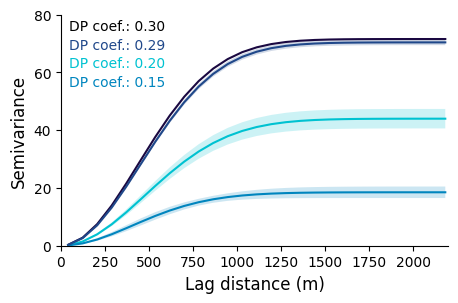

In [125]:
plt.figure(figsize=(5, 3))
plt.plot(gt_bin, gt_fit_model.variogram(gt_bin), label='Reference', color='#1a0841', linestyle='-', linewidth=1.5)
multicolors = ['#00c2d1', '#0085be', '#20488a']
lebels = ['Well', 'Plume', 'Geo']


plt.plot(gt_bin, np.mean(sparsewell_18_gamma_list, axis=0), color=multicolors[0], linestyle='-', linewidth=1.5, label=lebels[0])
plt.fill_between(gt_bin, np.mean(sparsewell_18_gamma_list, axis=0) - np.std(sparsewell_18_gamma_list, axis=0), 
                 np.mean(sparsewell_18_gamma_list, axis=0) + np.std(sparsewell_18_gamma_list, axis=0), 
                 color=multicolors[0], alpha=0.2, edgecolor='none')

plt.plot(gt_bin, np.mean(co2seismic_gamma_list, axis=0), color=multicolors[1], linestyle='-', linewidth=1.5, label=lebels[1])
plt.fill_between(gt_bin, np.mean(co2seismic_gamma_list, axis=0) - np.std(co2seismic_gamma_list, axis=0), 
                 np.mean(co2seismic_gamma_list, axis=0) + np.std(co2seismic_gamma_list, axis=0), 
                 color=multicolors[1], alpha=0.2, edgecolor='none')

plt.plot(gt_bin, np.mean(geoseismic_gamma_list, axis=0), color=multicolors[2], linestyle='-', linewidth=1.5, label=lebels[2])
plt.fill_between(gt_bin, np.mean(geoseismic_gamma_list, axis=0) - np.std(geoseismic_gamma_list, axis=0), 
                 np.mean(geoseismic_gamma_list, axis=0) + np.std(geoseismic_gamma_list, axis=0), 
                 color=multicolors[2], alpha=0.2, edgecolor='none')


plt.text(0.02, 0.98, f'DP coef.: {gt_dp:.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color='k')
plt.text(0.02, 0.82, f'DP coef.: {sparsewell_18_dp.mean():.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color=multicolors[0])
plt.text(0.02, 0.74, f'DP coef.: {co2seismic_dp.mean():.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color=multicolors[1])
plt.text(0.02, 0.90, f'DP coef.: {geoseismic_dp.mean():.2f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top', horizontalalignment='left', color=multicolors[2])

plt.xlabel('Lag distance (m)', fontsize=12)
plt.ylabel('Semivariance', fontsize=12)
plt.xlim(0, 2200)
plt.ylim(0, 80)
plt.yticks([0, 20, 40, 60, 80])

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('Topography_unstructured_outputs/[rebuttle]figs/[rebuttle]variogram_single.pdf', bbox_inches='tight')

## flow velocity

In [74]:
def calculate_center(gene, coords):
    long_axis = coords[:, 1]
    short_axis = coords[:, 0]
    
    saturation = gene[:, :, :, 1]
    saturation = np.where(saturation < 0.08, 0, saturation)  # set very small saturation to zero to avoid noise
    
    m0 = saturation.sum(axis=-1)
    m1_long = (saturation * long_axis).sum(axis=-1)
    m1_short = (saturation * short_axis).sum(axis=-1)
     
    center_long = m1_long / m0
    center_short = m1_short / m0
    
    return center_long, center_short

def calculate_gt_center(gt, coords):
    long_axis = coords[:, 1]
    short_axis = coords[:, 0]
    
    saturation = gt[:, :, 1]
    
    m0 = saturation.sum(axis=-1)
    m1_long = (saturation * long_axis).sum(axis=-1)
    m1_short = (saturation * short_axis).sum(axis=-1)
     
    center_long = m1_long / m0
    center_short = m1_short / m0
    
    return center_long, center_short

In [134]:
sparsewell_18_center_long, sparsewell_18_center_short = calculate_center(pred_sparsewell_18, coords)
co2seismic_center_long, co2seismic_center_short = calculate_center(pred_co2seismic, coords)
geoseismic_center_long, geoseismic_center_short = calculate_center(pred_geoseismic, coords)
sparsewell_and_co2seismic_center_long, sparsewell_and_co2seismic_center_short = calculate_center(pred_sparsewell_and_co2seismic, coords)
sparsewell_and_geoseismic_center_long, sparsewell_and_geoseismic_center_short = calculate_center(pred_sparsewell_and_geoseismic, coords)
co2seismic_and_geoseismic_center_long, co2seismic_and_geoseismic_center_short = calculate_center(pred_co2seismic_and_geoseismic, coords)
gt_center_long, gt_center_short = calculate_gt_center(ref, coords)
print(gt_center_long.shape, sparsewell_18_center_long.shape)

(128,) (10, 128)


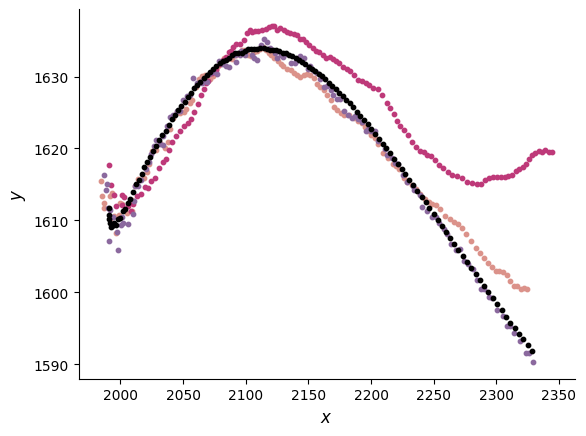

In [ ]:
plt.scatter(gt_center_long, gt_center_short, color='k', marker='o', s=10, label='Reference', zorder=1000)

multicolors = ['#DB928AFF', '#BE3979FF', '#8B699EFF']
lebels = ['Well+Plume', 'Well+Geo', 'Plume+Geo']

plt.scatter(sparsewell_and_co2seismic_center_long.mean(axis=0), sparsewell_and_co2seismic_center_short.mean(axis=0), color=multicolors[0], marker='o', s=10, label=lebels[0], zorder=3)
plt.scatter(sparsewell_and_geoseismic_center_long.mean(axis=0), sparsewell_and_geoseismic_center_short.mean(axis=0), color=multicolors[1], marker='o', s=10, label=lebels[1], zorder=3)
plt.scatter(co2seismic_and_geoseismic_center_long.mean(axis=0), co2seismic_and_geoseismic_center_short.mean(axis=0), color=multicolors[2], marker='o', s=10, label=lebels[2], zorder=3)
plt.xlabel('$x$', fontsize=12)
plt.ylabel('$y$', fontsize=12)


ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)



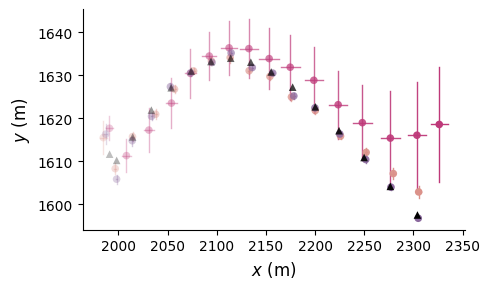

In [178]:
import matplotlib.colors as mcolors
import numpy as np

fig, ax = plt.subplots(figsize=(5, 3))

step = 8
time_idx = np.arange(0, 128, step)
n_points = len(time_idx)

def get_alpha_colors(base_color, n, alpha_min=0.25, alpha_max=1.0):
    rgba = mcolors.to_rgba(base_color)
    alphas = np.linspace(alpha_min, alpha_max, n)
    return [(*rgba[:3], a) for a in alphas]

# GT
gt_colors = get_alpha_colors('k', n_points)
for j, t in enumerate(time_idx):
    ax.scatter(gt_center_long[t], gt_center_short[t], color=gt_colors[j], marker='^', s=30, zorder=10000, edgecolors='none')

multicolors = ['#DB928AFF', '#BE3979FF', '#8B699EFF']
labels = ['Well+Plume', 'Well+Geo', 'Plume+Geo']
data_long = [sparsewell_and_co2seismic_center_long, sparsewell_and_geoseismic_center_long, co2seismic_and_geoseismic_center_long]
data_short = [sparsewell_and_co2seismic_center_short, sparsewell_and_geoseismic_center_short, co2seismic_and_geoseismic_center_short]

cap_len = 0.0

for k in range(3):
    colors = get_alpha_colors(multicolors[k], n_points)
    mean_long = data_long[k].mean(axis=0)
    mean_short = data_short[k].mean(axis=0)
    std_long = data_long[k].std(axis=0)
    std_short = data_short[k].std(axis=0)

    for j, t in enumerate(time_idx):
        ax.scatter(mean_long[t], mean_short[t], color=colors[j], s=30, zorder=3, edgecolors='none')
        ax.plot([mean_long[t] - std_long[t], mean_long[t] + std_long[t]],
                [mean_short[t], mean_short[t]], color=colors[j], lw=1)
        ax.plot([mean_long[t] - std_long[t]]*2, [mean_short[t] - cap_len, mean_short[t] + cap_len],
                color=colors[j], lw=1)
        ax.plot([mean_long[t] + std_long[t]]*2, [mean_short[t] - cap_len, mean_short[t] + cap_len],
                color=colors[j], lw=1)
        ax.plot([mean_long[t], mean_long[t]],
                [mean_short[t] - std_short[t], mean_short[t] + std_short[t]], color=colors[j], lw=1)
        ax.plot([mean_long[t] - cap_len, mean_long[t] + cap_len],
                [mean_short[t] - std_short[t]]*2, color=colors[j], lw=1)
        ax.plot([mean_long[t] - cap_len, mean_long[t] + cap_len],
                [mean_short[t] + std_short[t]]*2, color=colors[j], lw=1)


ax.set_xlabel('$x$ (m)', fontsize=12)
ax.set_ylabel('$y$ (m)', fontsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()

plt.savefig('Topography_unstructured_outputs/[rebuttle]figs/[rebuttle]center_multi.pdf', bbox_inches='tight')
plt.show()

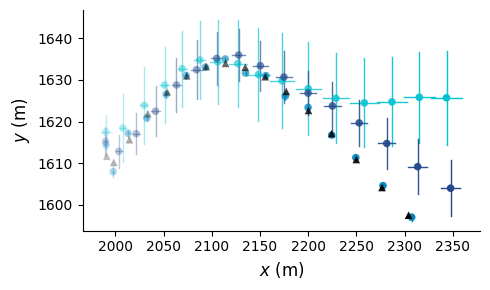

In [179]:
import matplotlib.colors as mcolors
import numpy as np

fig, ax = plt.subplots(figsize=(5, 3))

step = 8
time_idx = np.arange(0, 128, step)
n_points = len(time_idx)

def get_alpha_colors(base_color, n, alpha_min=0.25, alpha_max=1.0):
    rgba = mcolors.to_rgba(base_color)
    alphas = np.linspace(alpha_min, alpha_max, n)
    return [(*rgba[:3], a) for a in alphas]

# GT
gt_colors = get_alpha_colors('k', n_points)
for j, t in enumerate(time_idx):
    ax.scatter(gt_center_long[t], gt_center_short[t], color=gt_colors[j], marker='^', s=30, zorder=10000, edgecolors='none')

multicolors = ['#00c2d1', '#0085be', '#20488a']
labels = ['Well', 'Plume', 'Geo']
data_long = [sparsewell_18_center_long, co2seismic_center_long, geoseismic_center_long]
data_short = [sparsewell_18_center_short, co2seismic_center_short, geoseismic_center_short]

cap_len = 0.0

for k in range(3):
    colors = get_alpha_colors(multicolors[k], n_points)
    mean_long = data_long[k].mean(axis=0)
    mean_short = data_short[k].mean(axis=0)
    std_long = data_long[k].std(axis=0)
    std_short = data_short[k].std(axis=0)

    for j, t in enumerate(time_idx):
        ax.scatter(mean_long[t], mean_short[t], color=colors[j], s=30, zorder=3, edgecolors='none')
        ax.plot([mean_long[t] - std_long[t], mean_long[t] + std_long[t]],
                [mean_short[t], mean_short[t]], color=colors[j], lw=1)
        ax.plot([mean_long[t] - std_long[t]]*2, [mean_short[t] - cap_len, mean_short[t] + cap_len],
                color=colors[j], lw=1)
        ax.plot([mean_long[t] + std_long[t]]*2, [mean_short[t] - cap_len, mean_short[t] + cap_len],
                color=colors[j], lw=1)
        ax.plot([mean_long[t], mean_long[t]],
                [mean_short[t] - std_short[t], mean_short[t] + std_short[t]], color=colors[j], lw=1)
        ax.plot([mean_long[t] - cap_len, mean_long[t] + cap_len],
                [mean_short[t] - std_short[t]]*2, color=colors[j], lw=1)
        ax.plot([mean_long[t] - cap_len, mean_long[t] + cap_len],
                [mean_short[t] + std_short[t]]*2, color=colors[j], lw=1)


ax.set_xlabel('$x$ (m)', fontsize=12)
ax.set_ylabel('$y$ (m)', fontsize=12)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)


plt.tight_layout()

plt.savefig('Topography_unstructured_outputs/[rebuttle]figs/[rebuttle]center_single.pdf', bbox_inches='tight')
plt.show()

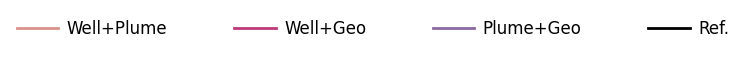

In [180]:
from matplotlib.lines import Line2D

multicolors = ['#DB928AFF', '#BE3979FF', '#8B699EFF']
labels = ['Well+Plume', 'Well+Geo', 'Plume+Geo']

legend_elements = [
    Line2D([0], [0], color=multicolors[0], lw=2, ls='-', label=labels[0]),
    Line2D([0], [0], color=multicolors[1], lw=2, ls='-', label=labels[1]),
    Line2D([0], [0], color=multicolors[2], lw=2, ls='-', label=labels[2]),
    Line2D([0], [0], color='k', lw=2, ls='-', label='Ref.'),
]

fig, ax = plt.subplots(figsize=(5, 0.5))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=4,
    frameon=False,
    handlelength=2.5,  # length of the legend lines
    handletextpad=0.5,  # space between the legend line and the text
    columnspacing=4,  # space between columns
    fontsize=12,
)

# plt.tight_layout()
plt.savefig('Topography_unstructured_outputs/[rebuttle]figs/LEGEND_LINE__multi.pdf', bbox_inches='tight')
plt.show()

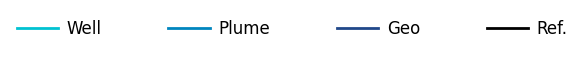

In [181]:
from matplotlib.lines import Line2D

multicolors = ['#00c2d1', '#0085be', '#20488a']
labels = ['Well', 'Plume', 'Geo']

legend_elements = [
    Line2D([0], [0], color=multicolors[0], lw=2, ls='-', label=labels[0]),
    Line2D([0], [0], color=multicolors[1], lw=2, ls='-', label=labels[1]),
    Line2D([0], [0], color=multicolors[2], lw=2, ls='-', label=labels[2]),
    Line2D([0], [0], color='k', lw=2, ls='-', label='Ref.'),
]

fig, ax = plt.subplots(figsize=(5, 0.5))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=4,
    frameon=False,
    handlelength=2.5,  # length of the legend lines
    handletextpad=0.5,  # space between the legend line and the text
    columnspacing=4,  # space between columns
    fontsize=12,
)

# plt.tight_layout()
plt.savefig('Topography_unstructured_outputs/[rebuttle]figs/LEGEND_LINE__single.pdf', bbox_inches='tight')
plt.show()

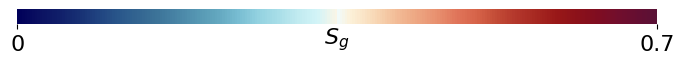

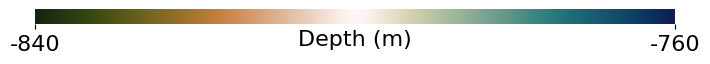

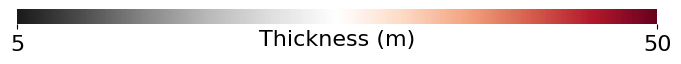

In [148]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors
from matplotlib.colors import LinearSegmentedColormap
import json

with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]

with open("depth_colormap.json", "r") as f:
    cmap_depth_json = json.load(f)[0]
    
with open("thickness_colormap.json", "r") as f:
    cmap_thickness_json = json.load(f)[0]

def get_color_map(cmap_json):
    rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)

    x = rgb_points[:, 0]

    r = rgb_points[:, 1]
    g = rgb_points[:, 2]
    b = rgb_points[:, 3]

    colors = list(zip(x, zip(r, g, b)))

    return LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)
mycmap = get_color_map(cmap_json)
mycmap_depth = get_color_map(cmap_depth_json)
mycmap_thickness = get_color_map(cmap_thickness_json)




cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.7)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(8, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([0, 0.7])
cbar.ax.set_xticklabels(["0", "0.7"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("Topography_unstructured_outputs/figs/sat_colorbar.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

# cmap = mycmap
# norm = colors.Normalize(vmin=12, vmax=16)
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
# sm.set_array([])

# fig = plt.figure(figsize=(8, 1.5))
# cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

# cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
# cbar.set_ticks([12, 16])
# cbar.ax.set_xticklabels(["12", "16"])
# cbar.outline.set_visible(False)
# cbar.ax.tick_params(labelsize=16)

# cbar_ax.text(0.5, -1.0, "$P$ (MPa)", transform=cbar_ax.transAxes,
#             fontsize=16, ha='center', va='center')

# plt.savefig("Topography_unstructured_outputs/figs/noise_level_sg.pdf", bbox_inches='tight')
# plt.show()

# -------------------------------------------

cmap = mycmap_depth
norm = colors.Normalize(vmin=-840, vmax=-760)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(8, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([-840, -760])
cbar.ax.set_xticklabels(["-840", "-760"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "Depth (m)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("Topography_unstructured_outputs/figs/depth_colorbar.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = plt.get_cmap('RdGy_r')
norm = colors.Normalize(vmin=5, vmax=50)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(8, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([5, 50])
cbar.ax.set_xticklabels(["5", "50"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "Thickness (m)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("Topography_unstructured_outputs/figs/thickness_colorbar.pdf", bbox_inches='tight')
plt.show()